# Where are the events? (world map)
Shows every image of the subset as a point on a world map, colored by event.

- **One point = one image.** Its position is the mean longitude/latitude of the buildings in that image (from the `lng_lat` polygons in the label files).
- Images with no buildings have no position, so they are not on the map.
- The data comes from `images.csv`, made by `scripts/make_subset.py`. Run that script first.
- Needs `plotly` (`conda install -c conda-forge plotly` or `pip install plotly`). If the figure does not show in VS Code, also install `nbformat`.
- The map background is loaded from the internet by plotly, so you need a connection.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
from IPython.display import display

# Folder made by make_subset.py (relative to this notebook in notebooks/)
SUBSET_DIR = Path("../xbd_subset/wind")
OUT_DIR = Path("../reports/eda")
OUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load the data

In [2]:
img = pd.read_csv(SUBSET_DIR / "images.csv")
print(f"{len(img):,} image pairs, {img['event'].nunique()} events")

has_pos = img["lon"].notna() & img["lat"].notna()
summary = img.assign(has_position=has_pos).groupby("event").agg(
    images=("image_id", "count"),
    with_position=("has_position", "sum"),
    splits=("orig_split", lambda s: ", ".join(sorted(s.unique()))),
)
display(summary)
print("Images without position (no buildings):", int((~has_pos).sum()))

pts = img[has_pos].copy()

1,674 image pairs, 5 events


,images,with_position,splits
event,,,
hurricane-matthew,405,379,"hold, test, tier1"
hurricane-michael,550,534,"hold, test, tier1"
joplin-tornado,149,148,tier3
moore-tornado,227,222,tier3
tuscaloosa-tornado,343,288,tier3


Images without position (no buildings): 103


## 2. World map
Hover a point to see the image id, split and number of buildings. Click an event name in the legend to hide or show it (double click to keep only that event).
Events are usually far apart, so on the world view each event looks like one dot. The next sections zoom in.

In [3]:
fig = px.scatter_geo(
    pts, lon="lon", lat="lat", color="event",
    hover_name="image_id",
    hover_data={"orig_split": True, "n_buildings": True, "lon": ":.3f", "lat": ":.3f", "event": False},
    projection="natural earth", opacity=0.7,
    title=f"Images per event ({SUBSET_DIR.name})",
)
fig.update_traces(marker=dict(size=6))
fig.update_geos(showcountries=True, countrycolor="gray", showcoastlines=True,
                showland=True, landcolor="rgb(240,240,240)", showocean=True, oceancolor="rgb(220,235,250)")
fig.update_layout(height=550, margin=dict(l=0, r=0, t=50, b=0))
fig.show()

fig.write_html(OUT_DIR / f"map_world_{SUBSET_DIR.name}.html")     # interactive file to share with the team

## 3. Center and size of each event
The size is the width and height of the box around all points of the event, in km (approximate: 1 degree of latitude = 111 km).
A small box means one area. A large box means the event covers a wide area, or it has far away images.

In [4]:
def box_km(g):
    lat0 = g["lat"].mean()
    return pd.Series({
        "lon_center": g["lon"].mean(),
        "lat_center": g["lat"].mean(),
        "north_south_km": (g["lat"].max() - g["lat"].min()) * 111.0,
        "east_west_km": (g["lon"].max() - g["lon"].min()) * 111.0 * np.cos(np.radians(lat0)),
        "n_points": len(g),
    })


centers = pts.groupby("event")[["lon", "lat"]].apply(box_km).round(2)
display(centers)
centers.to_csv(OUT_DIR / f"event_centers_{SUBSET_DIR.name}.csv")

,lon_center,lat_center,north_south_km,east_west_km,n_points
event,,,,,
hurricane-matthew,-73.98,18.43,53.31,66.40,379.0
hurricane-michael,-85.66,30.19,27.22,16.32,534.0
joplin-tornado,-94.49,37.07,3.39,11.31,148.0
moore-tornado,-97.48,35.33,5.04,10.93,222.0
tuscaloosa-tornado,-87.48,33.22,11.67,14.52,288.0


## 4. Zoom on each event
One map per event, zoomed on its points. Use the coordinates in the table above to find the exact place in a map app (type `latitude, longitude`).

In [5]:
for event, g in pts.groupby("event"):
    f = px.scatter_geo(
        g, lon="lon", lat="lat", color="orig_split",
        hover_name="image_id",
        hover_data={"n_buildings": True, "lon": ":.4f", "lat": ":.4f", "orig_split": False},
        projection="natural earth", opacity=0.8,
        title=f"{event}: {len(g)} images",
    )
    f.update_traces(marker=dict(size=7))
    f.update_geos(fitbounds="locations", resolution=50, showcountries=True, countrycolor="gray",
                  showcoastlines=True, showland=True, landcolor="rgb(240,240,240)",
                  showocean=True, oceancolor="rgb(220,235,250)", showsubunits=True, subunitcolor="lightgray")
    f.update_layout(height=450, margin=dict(l=0, r=0, t=50, b=0))
    f.show()

## 5. Plain plot without a background map
Use this only if the map background does not load (for example no internet). It shows the same points on longitude/latitude axes.

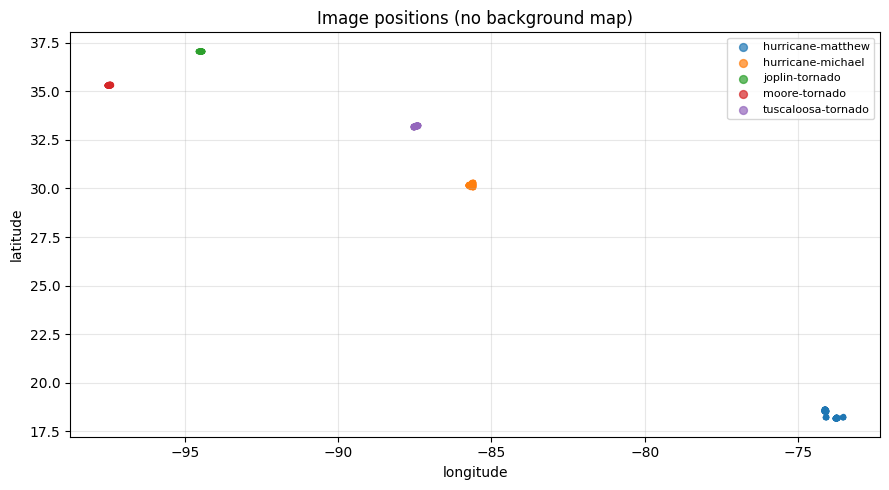

In [6]:
import matplotlib.pyplot as plt

fig2, ax = plt.subplots(figsize=(9, 5))
for event, g in pts.groupby("event"):
    ax.scatter(g["lon"], g["lat"], s=8, label=event, alpha=0.7)
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_title("Image positions (no background map)")
ax.grid(alpha=0.3)
ax.legend(markerscale=2, fontsize=8)
plt.tight_layout()
plt.show()